CELL 1 project introduction

In [ ]:
print("=" * 60)
print("GROUPDNA")
print("WhatsApp Group Chat Analyzer")
print("=" * 60)

print("""
GROUPDNA transforms WhatsApp conversations into
meaningful group insights using pure Python.

No Pandas
No NumPy
No Matplotlib
No Seaborn
No external analytics libraries
""")

GROUPDNA
WhatsApp Group Chat Analyzer

GROUPDNA transforms WhatsApp conversations into
meaningful group insights using pure Python.

No Pandas
No NumPy
No Matplotlib
No Seaborn
No external analytics libraries



cell 2 imports


In [ ]:
import re
import os
import zipfile
import json
import math

from collections import Counter, defaultdict
from datetime import datetime


uploading zip file

In [ ]:
from google.colab import files

uploaded = files.upload()

uploaded_filename = list(uploaded.keys())[0]

print("Uploaded file:", uploaded_filename)

Saving 13547360-hostel_bois (1).zip to 13547360-hostel_bois (1) (1).zip
Uploaded file: 13547360-hostel_bois (1) (1).zip


cell 4 extract zip

In [ ]:
extract_folder = "whatsapp_data"

os.makedirs(
    extract_folder,
    exist_ok=True
)

with zipfile.ZipFile(
    uploaded_filename,
    "r"
) as zip_file:

    zip_file.extractall(
        extract_folder
    )

print("ZIP extracted successfully.")

ZIP extracted successfully.


python

In [ ]:
for root, folders, filenames in os.walk(
    extract_folder
):

    for filename in filenames:

        print(
            os.path.join(
                root,
                filename
            )
        )

whatsapp_data/hostel_bois.txt
whatsapp_data/GroupDNA_Minor_Project_Brief.pdf


cell 5 find the text automatically

In [ ]:
txt_files = []

for root, folders, filenames in os.walk(
    extract_folder
):

    for filename in filenames:

        if filename.lower().endswith(".txt"):

            txt_files.append(
                os.path.join(
                    root,
                    filename
                )
            )

print("Chat files found:")

for file in txt_files:

    print(file)

Chat files found:
whatsapp_data/hostel_bois.txt


python

In [ ]:
if len(txt_files) == 0:

    raise FileNotFoundError(
        "No WhatsApp TXT chat file found."
    )

chat_file = txt_files[0]

print(
    "Using chat file:",
    chat_file
)

Using chat file: whatsapp_data/hostel_bois.txt


cell 6 read the whatsapp chat

In [ ]:
# CELL 6 - Read WhatsApp Chat

# Check whether Cell 5 found a chat file
if "chat_file" not in globals():
    print("ERROR: chat_file was not found.")
    print("Please run Cell 5 first.")
else:

    print("Reading chat file...")
    print("File:", chat_file)

    # Open the WhatsApp TXT file
    with open(chat_file, "r", encoding="utf-8-sig") as file:
        chat_text = file.read()

    # Basic information
    print()
    print("Chat file loaded successfully!")
    print("Total characters:", len(chat_text))
    print("Total lines:", len(chat_text.splitlines()))

    print()
    print("=" * 50)
    print("FIRST 20 LINES OF THE CHAT")
    print("=" * 50)

    # Display first 20 lines
    lines = chat_text.splitlines()

    for i, line in enumerate(lines[:20], start=1):
        print(i, ":", line)

Reading chat file...
File: whatsapp_data/hostel_bois.txt

Chat file loaded successfully!
Total characters: 249033
Total lines: 3178

FIRST 20 LINES OF THE CHAT
1 : 01/04/24, 01:12 - Messages and calls are end-to-end encrypted. No one outside of this chat, not even WhatsApp, can read or listen to them. Tap to learn more.
2 : 01/04/24, 01:13 - Priya created group "Hostel Bois 4ever"
3 : 01/04/24, 01:14 - Priya added you
4 : 01/04/24, 01:17 - Rahul: scene fix
5 : 01/04/24, 01:17 - Rahul: haan
6 : 01/04/24, 01:18 - Rahul: kya scene
7 : 01/04/24, 02:13 - Rahul: abhi free hai?
8 : 01/04/24, 02:13 - Rahul: abey
9 : 01/04/24, 02:14 - Rahul: bhai sun na
10 : 01/04/24, 07:46 - Priya: I have extra notes if anyone wants
11 : 01/04/24, 09:20 - Priya: Anyone needs help with anything?
12 : 01/04/24, 10:42 - Priya: Don't forget to call home guys
13 : 01/04/24, 11:37 - Rahul: ja yaar
14 : 01/04/24, 11:38 - Rahul: kya scene hai bhai
15 : 01/04/24, 11:38 - Rahul: bhai chai pite hai
16 : 01/04/24, 11:44 -

In [ ]:
# Regex patterns for WhatsApp chat messages
# User message pattern: Date, Time - Sender: Message
message_pattern_user = re.compile(r'^(\d{1,2}/\d{1,2}/\d{2,4}), (\d{1,2}:\d{2}) - ([^:]+): (.*)$')
# System message pattern: Date, Time - Message (e.g., group creation, encryption notifications)
message_pattern_system = re.compile(r'^(\d{1,2}/\d{1,2}/\d{2,4}), (\d{1,2}:\d{2}) - (.*)$')

parsed_messages = []

chat_lines = chat_text.splitlines()

for line in chat_lines:
    line = line.strip()
    if not line: # Skip empty lines
        continue

    match_user = message_pattern_user.match(line)
    if match_user:
        date_str, time_str, sender, message = match_user.groups()
        parsed_messages.append({
            'date': date_str,
            'time': time_str,
            'sender': sender.strip(),
            'message': message.strip(),
            'type': 'user'
        })
    else:
        match_system = message_pattern_system.match(line)
        if match_system:
            date_str, time_str, message = match_system.groups()
            parsed_messages.append({
                'date': date_str,
                'time': time_str,
                'sender': 'System', # Assign 'System' for system messages
                'message': message.strip(),
                'type': 'system'
            })
        else:
            # Handle multi-line messages: append to the last message if it's not a new message line
            if parsed_messages: # Ensure there's a previous message to append to
                parsed_messages[-1]['message'] += '\n' + line

print(f"Total messages parsed: {len(parsed_messages)}")
print("\nFirst 5 parsed messages:")
for i, msg in enumerate(parsed_messages[:5]):
    print(f"Message {i+1}:")
    for key, value in msg.items():
        print(f"  {key}: {value}")
    print("-" * 20)

Total messages parsed: 3178

First 5 parsed messages:
Message 1:
  date: 01/04/24
  time: 01:12
  sender: System
  message: Messages and calls are end-to-end encrypted. No one outside of this chat, not even WhatsApp, can read or listen to them. Tap to learn more.
  type: system
--------------------
Message 2:
  date: 01/04/24
  time: 01:13
  sender: System
  message: Priya created group "Hostel Bois 4ever"
  type: system
--------------------
Message 3:
  date: 01/04/24
  time: 01:14
  sender: System
  message: Priya added you
  type: system
--------------------
Message 4:
  date: 01/04/24
  time: 01:17
  sender: Rahul
  message: scene fix
  type: user
--------------------
Message 5:
  date: 01/04/24
  time: 01:17
  sender: Rahul
  message: haan
  type: user
--------------------


cell 7

In [ ]:
message_pattern = re.compile(
    r"^(\d{1,2}/\d{1,2}/\d{2,4}),\s+"
    r"(\d{1,2}:\d{2})\s+-\s+"
    r"([^:]+):\s?(.*)$"

)

cell 8 convert date and time

In [ ]:
# ============================================================
# CELL 8 - PREPARE WHATSAPP CHAT
# PURE PYTHON ONLY
# ============================================================

print("Starting Cell 8...")

# Check if chat_text exists
if "chat_text" not in globals():

    print("ERROR: chat_text is not available.")
    print("Please run Cell 6 first.")

else:

    # Convert chat into lines
    chat_lines = chat_text.splitlines()

    # Remove completely empty lines
    clean_lines = []

    for line in chat_lines:

        line = line.strip()

        if line != "":
            clean_lines.append(line)

    # Save cleaned chat
    clean_chat_text = "\n".join(clean_lines)

    # Count lines
    total_lines = len(clean_lines)

    print()
    print("=" * 50)
    print("CELL 8 COMPLETED")
    print("=" * 50)

    print("Original lines :", len(chat_lines))
    print("Clean lines    :", total_lines)

    print()
    print("First 10 chat lines:")
    print("-" * 50)

    for i in range(min(10, total_lines)):

        print(
            str(i + 1) + " : " + clean_lines[i]
        )

    print()
    print("Chat is ready for the next step.")

Starting Cell 8...

CELL 8 COMPLETED
Original lines : 3178
Clean lines    : 3178

First 10 chat lines:
--------------------------------------------------
1 : 01/04/24, 01:12 - Messages and calls are end-to-end encrypted. No one outside of this chat, not even WhatsApp, can read or listen to them. Tap to learn more.
2 : 01/04/24, 01:13 - Priya created group "Hostel Bois 4ever"
3 : 01/04/24, 01:14 - Priya added you
4 : 01/04/24, 01:17 - Rahul: scene fix
5 : 01/04/24, 01:17 - Rahul: haan
6 : 01/04/24, 01:18 - Rahul: kya scene
7 : 01/04/24, 02:13 - Rahul: abhi free hai?
8 : 01/04/24, 02:13 - Rahul: abey
9 : 01/04/24, 02:14 - Rahul: bhai sun na
10 : 01/04/24, 07:46 - Priya: I have extra notes if anyone wants

Chat is ready for the next step.


python

cell 9 remove  system messages

In [ ]:
# ============================================================
# CELL 9 - CHECK AND PREPARE CHAT DATA
# PURE PYTHON ONLY
# ============================================================

print("Starting Cell 9...")

# Check if clean_lines exists
if "clean_lines" not in globals():

    print("clean_lines not found.")
    print("Using chat_lines instead...")

    if "chat_lines" in globals():

        clean_lines = []

        for line in chat_lines:

            if line.strip() != "":
                clean_lines.append(line.strip())

    else:

        print("ERROR: Chat data not found.")
        print("Please run Cell 6 and Cell 8 first.")

else:

    print("clean_lines found.")


# ------------------------------------------------------------
# Create a simple list for the next cells
# ------------------------------------------------------------

if "clean_lines" in globals():

    chat_data = []

    for line in clean_lines:

        chat_data.append(line)


    # --------------------------------------------------------
    # Basic information
    # --------------------------------------------------------

    print()
    print("=" * 50)
    print("CELL 9 COMPLETED")
    print("=" * 50)

    print("Total chat lines:", len(chat_data))

    print()
    print("Sample chat data:")
    print("-" * 50)

    for i in range(min(5, len(chat_data))):

        print(
            str(i + 1) + " : " + chat_data[i]
        )

    print()
    print("Chat data is ready for the next cell.")

Starting Cell 9...
clean_lines found.

CELL 9 COMPLETED
Total chat lines: 3178

Sample chat data:
--------------------------------------------------
1 : 01/04/24, 01:12 - Messages and calls are end-to-end encrypted. No one outside of this chat, not even WhatsApp, can read or listen to them. Tap to learn more.
2 : 01/04/24, 01:13 - Priya created group "Hostel Bois 4ever"
3 : 01/04/24, 01:14 - Priya added you
4 : 01/04/24, 01:17 - Rahul: scene fix
5 : 01/04/24, 01:17 - Rahul: haan

Chat data is ready for the next cell.


cell 10 create master statsics

In [ ]:
# ============================================================
# CELL 10 - BASIC CHAT INFORMATION
# PURE PYTHON ONLY
# ============================================================

print("Starting Cell 10...")

# Check whether chat_data exists
if "chat_data" not in globals():

    print("ERROR: chat_data not found.")
    print("Please run Cell 9 first.")

else:

    # Total number of chat lines
    total_lines = len(chat_data)

    # Count lines that look like WhatsApp messages
    message_lines = []

    for line in chat_data:

        if " - " in line:

            message_lines.append(line)

    # Save total messages
    total_messages = len(message_lines)

    # Display result
    print()
    print("=" * 50)
    print("BASIC CHAT INFORMATION")
    print("=" * 50)

    print("Total chat lines :", total_lines)
    print("Possible messages:", total_messages)

    print()
    print("First 5 messages:")
    print("-" * 50)

    for i in range(min(5, len(message_lines))):

        print(
            str(i + 1) + " : " + message_lines[i]
        )

    print()
    print("CELL 10 COMPLETED SUCCESSFULLY")

Starting Cell 10...

BASIC CHAT INFORMATION
Total chat lines : 3178
Possible messages: 3178

First 5 messages:
--------------------------------------------------
1 : 01/04/24, 01:12 - Messages and calls are end-to-end encrypted. No one outside of this chat, not even WhatsApp, can read or listen to them. Tap to learn more.
2 : 01/04/24, 01:13 - Priya created group "Hostel Bois 4ever"
3 : 01/04/24, 01:14 - Priya added you
4 : 01/04/24, 01:17 - Rahul: scene fix
5 : 01/04/24, 01:17 - Rahul: haan

CELL 10 COMPLETED SUCCESSFULLY


 cell 11top contributors

1.   List item
2.   List item



In [ ]:
# ============================================================
# CELL 11 - PREPARE MESSAGE LINES
# PURE PYTHON ONLY
# ============================================================

print("Starting Cell 11...")

# Check if chat_data exists
if "chat_data" not in globals():

    print("ERROR: chat_data not found.")
    print("Please run Cell 9 first.")

else:

    # Create a new list
    message_lines = []

    # Go through every chat line
    for line in chat_data:

        # Remove extra spaces
        line = line.strip()

        # Keep lines containing the WhatsApp separator
        if " - " in line:

            message_lines.append(line)

    # Store the number of messages
    message_count = len(message_lines)

    # Display results
    print()
    print("=" * 50)
    print("CELL 11 COMPLETED")
    print("=" * 50)

    print("Message lines found:", message_count)

    print()
    print("First 5 message lines:")
    print("-" * 50)

    for i in range(min(5, message_count)):

        print(
            str(i + 1) + " : " + message_lines[i]
        )

    print()
    print("Message data is ready for Cell 12.")

Starting Cell 11...

CELL 11 COMPLETED
Message lines found: 3178

First 5 message lines:
--------------------------------------------------
1 : 01/04/24, 01:12 - Messages and calls are end-to-end encrypted. No one outside of this chat, not even WhatsApp, can read or listen to them. Tap to learn more.
2 : 01/04/24, 01:13 - Priya created group "Hostel Bois 4ever"
3 : 01/04/24, 01:14 - Priya added you
4 : 01/04/24, 01:17 - Rahul: scene fix
5 : 01/04/24, 01:17 - Rahul: haan

Message data is ready for Cell 12.


cell 12 most active member

In [ ]:
# ============================================================
# CELL 12 - EXTRACT WHATSAPP MESSAGES
# Pure Python - No Pandas / NumPy
# ============================================================

import re

print("Starting WhatsApp message extraction...")

# ------------------------------------------------------------
# Check whether chat_text exists
# ------------------------------------------------------------

if "chat_text" not in globals():

    print("ERROR: chat_text is not available.")
    print()
    print("Please run Cell 6 first.")

else:

    # --------------------------------------------------------
    # Split the complete chat into lines
    # --------------------------------------------------------

    lines = chat_text.splitlines()

    messages = []

    # --------------------------------------------------------
    # WhatsApp message pattern
    #
    # Supports:
    # 01/01/2024, 10:30 - Name: Message
    # 01/01/24, 10:30 - Name: Message
    # --------------------------------------------------------

    pattern = re.compile(
        r"^(\d{1,2}[/-]\d{1,2}[/-]\d{2,4}),\s*"
        r"(\d{1,2}:\d{2})\s*-\s*"
        r"(.*?):\s*(.*)$"
    )

    current_message = None

    # --------------------------------------------------------
    # Process every line
    # --------------------------------------------------------

    for line in lines:

        match = pattern.match(line)

        # ----------------------------------------------------
        # New WhatsApp message
        # ----------------------------------------------------

        if match:

            date = match.group(1)
            time = match.group(2)
            sender = match.group(3).strip()
            message = match.group(4).strip()

            current_message = {
                "date": date,
                "time": time,
                "sender": sender,
                "message": message
            }

            messages.append(
                current_message
            )

        # ----------------------------------------------------
        # Continuation of previous message
        # ----------------------------------------------------

        else:

            if (
                current_message is not None
                and line.strip() != ""
            ):

                current_message["message"] += (
                    "\n" + line.strip()
                )

    # --------------------------------------------------------
    # Results
    # --------------------------------------------------------

    print()
    print("=" * 60)
    print("MESSAGE EXTRACTION COMPLETED")
    print("=" * 60)

    print(
        "Total lines:",
        len(lines)
    )

    print(
        "Total messages:",
        len(messages)
    )

    # --------------------------------------------------------
    # Show first 10 messages
    # --------------------------------------------------------

    print()
    print("=" * 60)
    print("FIRST 10 MESSAGES")
    print("=" * 60)

    for i, item in enumerate(
        messages[:10],
        start=1
    ):

        print()
        print(
            i,
            "|",
            item["date"],
            "|",
            item["time"],
            "|",
            item["sender"]
        )

        print(
            "   ",
            item["message"][:150]
        )

    # --------------------------------------------------------
    # Store useful variables
    # --------------------------------------------------------

    total_messages = len(messages)

    print()
    print(
        "Total messages available for GroupDNA:",
        total_messages
    )

Starting WhatsApp message extraction...

MESSAGE EXTRACTION COMPLETED
Total lines: 3178
Total messages: 3174

FIRST 10 MESSAGES

1 | 01/04/24 | 01:17 | Rahul
    scene fix

2 | 01/04/24 | 01:17 | Rahul
    haan

3 | 01/04/24 | 01:18 | Rahul
    kya scene

4 | 01/04/24 | 02:13 | Rahul
    abhi free hai?

5 | 01/04/24 | 02:13 | Rahul
    abey

6 | 01/04/24 | 02:14 | Rahul
    bhai sun na

7 | 01/04/24 | 07:46 | Priya
    I have extra notes if anyone wants

8 | 01/04/24 | 09:20 | Priya
    Anyone needs help with anything?

9 | 01/04/24 | 10:42 | Priya
    Don't forget to call home guys

10 | 01/04/24 | 11:37 | Rahul
    ja yaar

Total messages available for GroupDNA: 3174


cell 13 message types

In [ ]:
message_types = {
    "Text Messages": 0,
    "Media": 0,
    "Links": 0,
    "Deleted Messages": 0
}

In [ ]:
then

In [ ]:
for msg in messages:

    text = msg["message"]

    lower_text = text.lower()

    if "<media omitted>" in lower_text:

        message_types["Media"] += 1

    elif "this message was deleted" in lower_text:

        message_types[
            "Deleted Messages"
        ] += 1

    elif re.search(
        r"https?://|www\.",
        text,
        re.IGNORECASE
    ):

        message_types["Links"] += 1

    else:

        message_types[
            "Text Messages"
        ] += 1

print

In [ ]:
for category, count in message_types.items():

    print(
        category,
        ":",
        count
    )

Text Messages : 3127
Media : 32
Links : 0
Deleted Messages : 15


cell 14 busisest day

In [ ]:
# ============================================================
# CELL 14 - FIND GROUP MEMBERS
# Pure Python - No Pandas / NumPy
# ============================================================

print("Finding WhatsApp group members...")

# ------------------------------------------------------------
# Check whether messages exists
# ------------------------------------------------------------

if "messages" not in globals():

    print("ERROR: 'messages' was not found.")
    print()
    print("Please run Cell 12 successfully first.")

else:

    # --------------------------------------------------------
    # Create a set of unique senders
    # --------------------------------------------------------

    members_set = set()

    for item in messages:

        sender = item.get("sender", "").strip()

        if sender != "":

            members_set.add(sender)

    # --------------------------------------------------------
    # Convert set to sorted list
    # --------------------------------------------------------

    members = sorted(
        members_set,
        key=str.lower
    )

    # --------------------------------------------------------
    # Total members
    # --------------------------------------------------------

    total_members = len(members)

    # --------------------------------------------------------
    # Display results
    # --------------------------------------------------------

    print()
    print("=" * 60)
    print("GROUP MEMBERS")
    print("=" * 60)

    print(
        "Total members:",
        total_members
    )

    print()

    for number, member in enumerate(
        members,
        start=1
    ):

        print(
            number,
            ".",
            member
        )

    print()
    print("=" * 60)
    print("MEMBER EXTRACTION COMPLETED")
    print("=" * 60)

Finding WhatsApp group members...

GROUP MEMBERS
Total members: 6

1 . Aman
2 . Karan
3 . Neha
4 . Priya
5 . Rahul
6 . Vikas

MEMBER EXTRACTION COMPLETED


cell 15 peak hour

In [ ]:
# ============================================================
# CELL 15 - MESSAGE COUNT BY MEMBER
# PURE PYTHON ONLY
# ============================================================

print("Starting Cell 15...")

# Check if messages exists
if "messages" not in globals():

    print("ERROR: messages was not found.")
    print("Please run Cell 12 first.")

else:

    # Dictionary to store message counts
    member_message_count = {}

    # Go through every message
    for item in messages:

        # Get sender
        sender = item.get("sender", "").strip()

        # Ignore empty sender names
        if sender == "":
            continue

        # Add sender to dictionary if not present
        if sender not in member_message_count:

            member_message_count[sender] = 0

        # Increase message count
        member_message_count[sender] += 1

    # Sort members by number of messages
    sorted_members = sorted(
        member_message_count.items(),
        key=lambda x: x[1],
        reverse=True
    )

    # Display results
    print()
    print("=" * 50)
    print("MESSAGE COUNT BY MEMBER")
    print("=" * 50)

    print(
        "Total members:",
        len(sorted_members)
    )

    print()

    for number, item in enumerate(
        sorted_members,
        start=1
    ):

        name = item[0]
        count = item[1]

        print(
            str(number) + ".",
            name,
            "→",
            count,
            "messages"
        )

    print()
    print("CELL 15 COMPLETED SUCCESSFULLY")

Starting Cell 15...

MESSAGE COUNT BY MEMBER
Total members: 6

1. Rahul → 953 messages
2. Priya → 718 messages
3. Neha → 635 messages
4. Aman → 490 messages
5. Karan → 354 messages
6. Vikas → 24 messages

CELL 15 COMPLETED SUCCESSFULLY


cell 16  daily activity

In [ ]:
# ============================================================
# CELL 16 - MEMBER ACTIVITY PERCENTAGE
# PURE PYTHON ONLY
# ============================================================

print("Starting Cell 16...")

# Check if Cell 15 created the message count
if "member_message_count" not in globals():

    print("ERROR: member_message_count not found.")
    print("Please run Cell 15 first.")

else:

    # Calculate total messages
    total = 0

    for name in member_message_count:
        total += member_message_count[name]

    # Avoid division by zero
    if total == 0:

        print("No messages were found.")

    else:

        # Dictionary for percentages
        member_percentage = {}

        # Calculate percentage
        for name in member_message_count:

            count = member_message_count[name]

            percentage = (
                count / total
            ) * 100

            member_percentage[name] = percentage

        # Sort by percentage
        sorted_percentage = sorted(
            member_percentage.items(),
            key=lambda x: x[1],
            reverse=True
        )

        # Display results
        print()
        print("=" * 55)
        print("MEMBER ACTIVITY PERCENTAGE")
        print("=" * 55)

        print(
            "Total messages:",
            total
        )

        print()

        for number, item in enumerate(
            sorted_percentage,
            start=1
        ):

            name = item[0]
            percentage = item[1]

            print(
                str(number) + ".",
                name,
                "→",
                round(percentage, 2),
                "%"
            )

        print()
        print("CELL 16 COMPLETED SUCCESSFULLY")

Starting Cell 16...

MEMBER ACTIVITY PERCENTAGE
Total messages: 3174

1. Rahul → 30.03 %
2. Priya → 22.62 %
3. Neha → 20.01 %
4. Aman → 15.44 %
5. Karan → 11.15 %
6. Vikas → 0.76 %

CELL 16 COMPLETED SUCCESSFULLY


cell 17 hourly activity

In [ ]:
hourly_activity = {}

for hour in range(24):

    hourly_activity[hour] = (
        hour_counts.get(hour, 0)
    )

cell 18 activity heat map

In [ ]:
# ============================================================
# CELL 18 - MOST ACTIVE MEMBER
# PURE PYTHON ONLY
# ============================================================

print("Starting Cell 18...")

# Check if message counts are available
if "member_message_count" not in globals():

    print("ERROR: member_message_count not found.")
    print("Please run Cell 15 first.")

else:

    # Check whether the dictionary contains members
    if len(member_message_count) == 0:

        print("No member data found.")

    else:

        # Find the member with the highest message count
        most_active_member = ""
        highest_messages = 0

        for name in member_message_count:

            count = member_message_count[name]

            if count > highest_messages:

                highest_messages = count
                most_active_member = name

        # Display result
        print()
        print("=" * 55)
        print("GROUPDNA - MOST ACTIVE MEMBER")
        print("=" * 55)

        print()
        print(
            "Most active member:",
            most_active_member
        )

        print(
            "Messages sent:",
            highest_messages
        )

        # Store useful variables for later cells
        top_member = most_active_member
        top_member_messages = highest_messages

        print()
        print("CELL 18 COMPLETED SUCCESSFULLY")

Starting Cell 18...

GROUPDNA - MOST ACTIVE MEMBER

Most active member: Rahul
Messages sent: 953

CELL 18 COMPLETED SUCCESSFULLY


cell 19 top words

In [ ]:
stop_words = {
    "the", "a", "an",
    "and", "or", "but",
    "is", "are", "was",
    "were", "to", "of",
    "in", "on", "for",
    "with", "this", "that",
    "you", "your", "i",
    "we", "it", "my",
    "me", "he", "she",
    "they", "them",
    "have", "has",
    "had", "be",
    "been", "am",
    "do", "did",
    "so", "if",
    "at", "from",
    "as", "just"
}

count

In [ ]:
word_counts = Counter()

for msg in messages:

    words = re.findall(
        r"[A-Za-z]+",
        msg["message"].lower()
    )

    for word in words:

        if (
            len(word) >= 3
            and word not in stop_words
        ):

            word_counts[word] += 1

top words

In [ ]:
top_words = (
    word_counts
    .most_common(15)
)

print("TOP WORDS")

for word, count in top_words:

    print(
        word,
        "→",
        count
    )

TOP WORDS
how → 321
guys → 318
today → 292
about → 274
hai → 268
his → 217
everyone → 203
which → 202
telling → 179
bhai → 160
anyone → 157
one → 157
started → 150
scene → 145
entire → 145


cell 20 emoji analysis

In [ ]:
emoji_counts = Counter()

for msg in messages:

    for character in msg["message"]:

        code = ord(character)

        if (
            0x1F300 <= code <= 0x1FAFF
            or
            0x2600 <= code <= 0x27BF
        ):

            emoji_counts[
                character
            ] += 1

then

In [ ]:
top_emojis = (
    emoji_counts
    .most_common(10)
)

print("MOST USED EMOJIS")

for emoji, count in top_emojis:

    print(
        emoji,
        "→",
        count
    )

MOST USED EMOJIS


cell 21 emoji king

In [ ]:
emoji_by_user = Counter()

for msg in messages:

    for character in msg["message"]:

        code = ord(character)

        if (
            0x1F300 <= code <= 0x1FAFF
            or
            0x2600 <= code <= 0x27BF
        ):

            emoji_by_user[
                msg["sender"]
            ] += 1

emoji

In [ ]:
if emoji_by_user:
    emoji_king = (
        emoji_by_user
        .most_common(1)[0]
    )

    print(
        "😂 Emoji King:",
        emoji_king[0]
    )

    print(
        "Emoji count:",
        emoji_king[1]
    )
else:
    print("No emojis were found in the chat.")

No emojis were found in the chat.


cell 22 night owl

In [ ]:
# ============================================================
# CELL 22 - BUSIEST HOUR
# PURE PYTHON ONLY
# ============================================================

print("Starting Cell 22...")

# Check whether messages exist
if "messages" not in globals():

    print("ERROR: messages not found.")
    print("Please run Cell 12 first.")

else:

    # Dictionary to count messages by hour
    hour_count = {}

    # Go through all messages
    for item in messages:

        time_text = item.get("time", "")

        # Get the hour from HH:MM
        if ":" in time_text:

            hour_text = time_text.split(":")[0]

            try:

                hour = int(hour_text)

            except:

                continue

            # Count the hour
            if hour not in hour_count:

                hour_count[hour] = 0

            hour_count[hour] += 1

    # --------------------------------------------------------
    # Find busiest hour
    # --------------------------------------------------------

    if len(hour_count) == 0:

        print("No valid time information found.")

    else:

        busiest_hour = None
        highest_count = 0

        for hour in hour_count:

            count = hour_count[hour]

            if count > highest_count:

                highest_count = count
                busiest_hour = hour

        # Save variables for later cells
        peak_hour = busiest_hour
        peak_hour_messages = highest_count

        # ----------------------------------------------------
        # Display result
        # ----------------------------------------------------

        print()
        print("=" * 55)
        print("GROUPDNA - BUSIEST HOUR")
        print("=" * 55)

        print()

        print(
            "Busiest hour:",
            str(busiest_hour) + ":00"
        )

        print(
            "Messages during this hour:",
            highest_count
        )

        print()
        print("All hourly activity:")

        for hour in sorted(hour_count):

            print(
                str(hour).zfill(2) + ":00 →",
                hour_count[hour],
                "messages"
            )

        print()
        print("CELL 22 COMPLETED SUCCESSFULLY")

Starting Cell 22...

GROUPDNA - BUSIEST HOUR

Busiest hour: 18:00
Messages during this hour: 248

All hourly activity:
00:00 → 57 messages
01:00 → 82 messages
02:00 → 83 messages
03:00 → 77 messages
04:00 → 110 messages
05:00 → 29 messages
06:00 → 33 messages
07:00 → 55 messages
08:00 → 122 messages
09:00 → 151 messages
10:00 → 160 messages
11:00 → 114 messages
12:00 → 193 messages
13:00 → 159 messages
14:00 → 162 messages
15:00 → 131 messages
16:00 → 189 messages
17:00 → 173 messages
18:00 → 248 messages
19:00 → 228 messages
20:00 → 166 messages
21:00 → 177 messages
22:00 → 116 messages
23:00 → 159 messages

CELL 22 COMPLETED SUCCESSFULLY


cell 23 longest message

In [ ]:
# ============================================================
# CELL 23 - LONGEST MESSAGE
# PURE PYTHON ONLY
# ============================================================

print("Starting Cell 23...")

# Check if messages are available
if "messages" not in globals():

    print("ERROR: messages not found.")
    print("Please run Cell 12 first.")

else:

    # Check if messages contain data
    if len(messages) == 0:

        print("ERROR: No messages found.")

    else:

        # ----------------------------------------------------
        # Find longest message
        # ----------------------------------------------------

        longest_message = None
        longest_length = 0

        for item in messages:

            message_text = item.get(
                "message",
                ""
            )

            # Make sure it is a string
            if not isinstance(
                message_text,
                str
            ):
                continue

            message_length = len(
                message_text
            )

            if message_length > longest_length:

                longest_length = message_length

                longest_message = item

        # ----------------------------------------------------
        # Display result
        # ----------------------------------------------------

        if longest_message is None:

            print("No valid messages found.")

        else:

            print()
            print("=" * 60)
            print("GROUPDNA - LONGEST MESSAGE")
            print("=" * 60)

            print()

            print(
                "Sender:",
                longest_message.get(
                    "sender",
                    "Unknown"
                )
            )

            print(
                "Date:",
                longest_message.get(
                    "date",
                    "Unknown"
                )
            )

            print(
                "Time:",
                longest_message.get(
                    "time",
                    "Unknown"
                )
            )

            print(
                "Character count:",
                longest_length
            )

            print()

            print("Longest message:")
            print("-" * 60)

            print(
                longest_message.get(
                    "message",
                    ""
                )
            )

            print("-" * 60)

            # Save variables for later cells
            longest_message_text = (
                longest_message.get(
                    "message",
                    ""
                )
            )

            longest_message_sender = (
                longest_message.get(
                    "sender",
                    "Unknown"
                )
            )

            print()
            print("CELL 23 COMPLETED SUCCESSFULLY")

Starting Cell 23...

GROUPDNA - LONGEST MESSAGE

Sender: Karan
Date: 02/04/24
Time: 19:34
Character count: 364

Longest message:
------------------------------------------------------------
Guys you wont believe what happened today, so I was going to the cafeteria and there was this whole drama about the dosa machine being broken and the cook started telling everyone about how he had warned the management three times but no one listened, and then a guy from third year came and started arguing about how he had been waiting for forty minutes already.
------------------------------------------------------------

CELL 23 COMPLETED SUCCESSFULLY


cell 24 average message length

In [ ]:
# ============================================================
# CELL 24 - AVERAGE MESSAGE LENGTH
# PURE PYTHON ONLY
# ============================================================

print("Starting Cell 24...")

if "messages" not in globals():

    print("ERROR: messages not found.")
    print("Please run Cell 12 first.")

else:

    total_characters = 0
    valid_messages = 0

    for item in messages:

        text = item.get("message", "")

        if isinstance(text, str):

            total_characters += len(text)
            valid_messages += 1

    if valid_messages == 0:

        print("No valid messages found.")

    else:

        average_length = (
            total_characters / valid_messages
        )

        # Save for later GroupDNA cells
        avg_message_length = average_length

        print()
        print("=" * 55)
        print("GROUPDNA - AVERAGE MESSAGE LENGTH")
        print("=" * 55)

        print()
        print(
            "Total messages:",
            valid_messages
        )

        print(
            "Total characters:",
            total_characters
        )

        print(
            "Average message length:",
            round(average_length, 2),
            "characters"
        )

        print()
        print("CELL 24 COMPLETED SUCCESSFULLY")

Starting Cell 24...

GROUPDNA - AVERAGE MESSAGE LENGTH

Total messages: 3174
Total characters: 167385
Average message length: 52.74 characters

CELL 24 COMPLETED SUCCESSFULLY


cell 25 coversation starter

In [ ]:
# ============================================================
# CELL 25 - CONVERSATION STARTER
# PURE PYTHON ONLY
# ============================================================

print("Starting Cell 25...")

if "messages" not in globals():

    print("ERROR: messages not found.")
    print("Please run Cell 12 first.")

else:

    # Dictionary to count who starts conversations
    starter_count = {}

    # Store the previous date
    previous_date = ""

    # Go through messages
    for item in messages:

        current_date = item.get("date", "")
        sender = item.get("sender", "")

        # Ignore incomplete messages
        if current_date == "" or sender == "":
            continue

        # If the date changes, this is the first
        # message of a new conversation/day
        if current_date != previous_date:

            if sender not in starter_count:
                starter_count[sender] = 0

            starter_count[sender] += 1

            previous_date = current_date

    # --------------------------------------------------------
    # Find the main conversation starter
    # --------------------------------------------------------

    if len(starter_count) == 0:

        print("No conversation starter data found.")

    else:

        sorted_starters = sorted(
            starter_count.items(),
            key=lambda x: x[1],
            reverse=True
        )

        conversation_starter = sorted_starters[0][0]
        conversation_starter_count = sorted_starters[0][1]

        # Save variables for later cells
        top_conversation_starter = conversation_starter
        top_conversation_starter_count = conversation_starter_count

        # ----------------------------------------------------
        # Display results
        # ----------------------------------------------------

        print()
        print("=" * 60)
        print("GROUPDNA - CONVERSATION STARTER")
        print("=" * 60)

        print()

        print(
            "Top conversation starter:",
            conversation_starter
        )

        print(
            "Conversations started:",
            conversation_starter_count
        )

        print()
        print("Conversation starters by member:")
        print("-" * 60)

        for number, item in enumerate(
            sorted_starters,
            start=1
        ):

            name = item[0]
            count = item[1]

            print(
                str(number) + ".",
                name,
                "→",
                count,
                "starts"
            )

        print()
        print("CELL 25 COMPLETED SUCCESSFULLY")

Starting Cell 25...

GROUPDNA - CONVERSATION STARTER

Top conversation starter: Aman
Conversations started: 58

Conversation starters by member:
------------------------------------------------------------
1. Aman → 58 starts
2. Rahul → 2 starts

CELL 25 COMPLETED SUCCESSFULLY


cell 26 response time

In [ ]:
# ============================================================
# CELL 26 - RESPONSE TIME ANALYSIS
# PURE PYTHON ONLY
# ============================================================

print("Starting Cell 26...")

if "messages" not in globals():

    print("ERROR: messages not found.")
    print("Please run Cell 12 first.")

else:

    import datetime

    response_times = {}

    # --------------------------------------------------------
    # Convert date + time into a datetime
    # --------------------------------------------------------

    def get_datetime(item):

        date_text = item.get("date", "")
        time_text = item.get("time", "")

        try:

            parts = date_text.replace("-", "/").split("/")

            if len(parts) != 3:
                return None

            day = int(parts[0])
            month = int(parts[1])
            year = int(parts[2])

            if year < 100:
                year = 2000 + year

            hour = int(time_text.split(":")[0])
            minute = int(time_text.split(":")[1])

            return datetime.datetime(
                year,
                month,
                day,
                hour,
                minute
            )

        except:

            return None

    # --------------------------------------------------------
    # Compare consecutive messages
    # --------------------------------------------------------

    for i in range(1, len(messages)):

        previous = messages[i - 1]
        current = messages[i]

        previous_sender = previous.get("sender", "")
        current_sender = current.get("sender", "")

        # Only count replies from another person
        if (
            previous_sender == ""
            or current_sender == ""
            or previous_sender == current_sender
        ):
            continue

        previous_time = get_datetime(previous)
        current_time = get_datetime(current)

        if (
            previous_time is None
            or current_time is None
        ):
            continue

        difference = (
            current_time - previous_time
        ).total_seconds() / 60

        # Ignore impossible/very long gaps
        if difference > 0 and difference <= 1440:

            if current_sender not in response_times:
                response_times[current_sender] = []

            response_times[current_sender].append(
                difference
            )

    # --------------------------------------------------------
    # Calculate average response time
    # --------------------------------------------------------

    average_response = {}

    for person in response_times:

        times = response_times[person]

        if len(times) > 0:

            total = 0

            for value in times:
                total += value

            average_response[person] = (
                total / len(times)
            )

    # --------------------------------------------------------
    # Display results
    # --------------------------------------------------------

    print()
    print("=" * 60)
    print("GROUPDNA - RESPONSE TIME ANALYSIS")
    print("=" * 60)

    if len(average_response) == 0:

        print()
        print("No response-time data could be calculated.")

    else:

        sorted_response = sorted(
            average_response.items(),
            key=lambda x: x[1]
        )

        print()

        for number, item in enumerate(
            sorted_response,
            start=1
        ):

            person = item[0]
            minutes = item[1]

            print(
                str(number) + ".",
                person,
                "→",
                round(minutes, 2),
                "minutes average"
            )

        # Fastest responder
        fastest_responder = sorted_response[0][0]
        fastest_response_time = sorted_response[0][1]

        print()
        print("-" * 60)

        print(
            "Fastest responder:",
            fastest_responder
        )

        print(
            "Average response time:",
            round(
                fastest_response_time,
                2
            ),
            "minutes"
        )

    print()
    print("CELL 26 COMPLETED SUCCESSFULLY")

Starting Cell 26...

GROUPDNA - RESPONSE TIME ANALYSIS

1. Rahul → 36.51 minutes average
2. Karan → 37.54 minutes average
3. Neha → 40.94 minutes average
4. Priya → 42.98 minutes average
5. Vikas → 46.3 minutes average
6. Aman → 56.94 minutes average

------------------------------------------------------------
Fastest responder: Rahul
Average response time: 36.51 minutes

CELL 26 COMPLETED SUCCESSFULLY


cell 27 group engagement score

In [ ]:
# ============================================================
# CELL 27 - GROUP ENGAGEMENT SCORE
# PURE PYTHON ONLY
# ============================================================

print("Starting Cell 27...")

# Check if messages exist
if "messages" not in globals():

    print("ERROR: messages not found.")
    print("Please run Cell 12 first.")

else:

    # Total number of messages
    total_messages = len(messages)

    # --------------------------------------------------------
    # Calculate Activity Score
    # --------------------------------------------------------

    activity_score = (
        total_messages / 3000
    ) * 100

    # Maximum score = 100
    if activity_score > 100:
        activity_score = 100

    # --------------------------------------------------------
    # Calculate Member Score
    # --------------------------------------------------------

    if "member_message_count" in globals():

        total_members = len(
            member_message_count
        )

    else:

        total_members = 0

        unique_members = set()

        for item in messages:

            sender = item.get(
                "sender",
                ""
            ).strip()

            if sender != "":
                unique_members.add(sender)

        total_members = len(unique_members)

    member_score = (
        total_members / 10
    ) * 100

    if member_score > 100:
        member_score = 100

    # --------------------------------------------------------
    # Final GroupDNA Score
    # --------------------------------------------------------

    engagement_score = (
        activity_score * 0.7
        +
        member_score * 0.3
    )

    if engagement_score > 100:
        engagement_score = 100

    # Save variables
    group_engagement_score = engagement_score
    group_activity_score = activity_score
    group_member_score = member_score

    # --------------------------------------------------------
    # Display result
    # --------------------------------------------------------

    print()
    print("=" * 60)
    print("GROUPDNA - GROUP ENGAGEMENT SCORE")
    print("=" * 60)

    print()

    print(
        "Total messages:",
        total_messages
    )

    print(
        "Total members:",
        total_members
    )

    print(
        "Activity score:",
        round(activity_score, 2),
        "/ 100"
    )

    print(
        "Member score:",
        round(member_score, 2),
        "/ 100"
    )

    print()

    print(
        "GROUP ENGAGEMENT SCORE:",
        round(engagement_score, 2),
        "/ 100"
    )

    print()

    # --------------------------------------------------------
    # Engagement level
    # --------------------------------------------------------

    if engagement_score >= 80:

        engagement_level = "Highly Active"

    elif engagement_score >= 60:

        engagement_level = "Very Active"

    elif engagement_score >= 40:

        engagement_level = "Moderately Active"

    elif engagement_score >= 20:

        engagement_level = "Less Active"

    else:

        engagement_level = "Quiet Group"

    print(
        "Engagement level:",
        engagement_level
    )

    print()
    print("CELL 27 COMPLETED SUCCESSFULLY")

Starting Cell 27...

GROUPDNA - GROUP ENGAGEMENT SCORE

Total messages: 3174
Total members: 6
Activity score: 100 / 100
Member score: 60.0 / 100

GROUP ENGAGEMENT SCORE: 88.0 / 100

Engagement level: Highly Active

CELL 27 COMPLETED SUCCESSFULLY


cell 28 generate automatic insights

In [ ]:
# ============================================================
# CELL 28 - AUTOMATIC GROUPDNA INSIGHTS
# PURE PYTHON ONLY
# ============================================================

print("Starting Cell 28...")

# ------------------------------------------------------------
# Create insights list
# ------------------------------------------------------------

insights = []

# ------------------------------------------------------------
# 1. Most active member
# ------------------------------------------------------------

if "top_member" in globals():

    most_active = top_member

elif "member_message_count" in globals() and len(member_message_count) > 0:

    most_active = max(
        member_message_count,
        key=member_message_count.get
    )

else:

    most_active = "Unknown"


insights.append(
    str(most_active)
    + " is the most active member."
)


# ------------------------------------------------------------
# 2. Find busiest day directly from messages
# ------------------------------------------------------------

day_count = {}

if "messages" in globals():

    import datetime

    for item in messages:

        date_text = item.get("date", "")

        try:

            parts = date_text.replace("-", "/").split("/")

            if len(parts) != 3:
                continue

            day = int(parts[0])
            month = int(parts[1])
            year = int(parts[2])

            if year < 100:
                year = 2000 + year

            date_object = datetime.date(
                year,
                month,
                day
            )

            weekday = date_object.strftime("%A")

            if weekday not in day_count:
                day_count[weekday] = 0

            day_count[weekday] += 1

        except:

            continue


# Find busiest day

if len(day_count) > 0:

    busiest_day = max(
        day_count,
        key=day_count.get
    )

    busiest_day_count = day_count[busiest_day]

    insights.append(
        str(busiest_day)
        + " is the busiest day with "
        + str(busiest_day_count)
        + " messages."
    )

else:

    busiest_day = "Unknown"

    insights.append(
        "Busiest day could not be calculated."
    )


# ------------------------------------------------------------
# 3. Total messages
# ------------------------------------------------------------

if "messages" in globals():

    total_messages = len(messages)

    insights.append(
        "The group has "
        + str(total_messages)
        + " total messages."
    )


# ------------------------------------------------------------
# 4. Engagement insight
# ------------------------------------------------------------

if "group_engagement_score" in globals():

    score = group_engagement_score

    if score >= 80:

        insights.append(
            "The group has very high engagement."
        )

    elif score >= 60:

        insights.append(
            "The group has strong engagement."
        )

    elif score >= 40:

        insights.append(
            "The group has moderate engagement."
        )

    else:

        insights.append(
            "The group has relatively low engagement."
        )


# ------------------------------------------------------------
# 5. Longest message insight
# ------------------------------------------------------------

if "longest_message_text" in globals():

    longest_length = len(
        longest_message_text
    )

    insights.append(
        "The longest message contains "
        + str(longest_length)
        + " characters."
    )


# ------------------------------------------------------------
# Display all insights
# ------------------------------------------------------------

print()
print("=" * 65)
print("GROUPDNA - AUTOMATIC INSIGHTS")
print("=" * 65)

print()

for number, insight in enumerate(
    insights,
    start=1
):

    print(
        str(number)
        + ". "
        + insight
    )


print()
print("=" * 65)
print("CELL 28 COMPLETED SUCCESSFULLY")
print("=" * 65)

Starting Cell 28...

GROUPDNA - AUTOMATIC INSIGHTS

1. Rahul is the most active member.
2. Wednesday is the busiest day with 483 messages.
3. The group has 3174 total messages.
4. The group has very high engagement.
5. The longest message contains 364 characters.

CELL 28 COMPLETED SUCCESSFULLY


GroupDNA_Dashboard.svg

cell 29 svg helper functions

In [ ]:
def svg_text(
    x,
    y,
    text,
    size=20,
    color="#333333",
    weight="normal",
    anchor="start"
):

    safe_text = (
        str(text)
        .replace("&", "&amp;")
        .replace("<", "&lt;")
        .replace(">", "&gt;")
    )

    return f"""
    <text
        x="{x}"
        y="{y}"
        font-size="{size}px"
        font-family="Arial"
        font-weight="{weight}"
        fill="{color}"
        text-anchor="{anchor}"
    >
        {safe_text}
    </text>
    """

cell 30 svg rectangles

In [ ]:
def svg_rect(
    x,
    y,
    width,
    height,
    fill="#FFFFFF",
    stroke="#DDDDDD",
    radius=12
):

    return f"""
    <rect
        x="{x}"
        y="{y}"
        width="{width}"
        height="{height}"
        rx="{radius}"
        fill="{fill}"
        stroke="{stroke}"
    />
    """

cell 31 create KPI card

In [ ]:
def create_kpi_card(
    x,
    y,
    title,
    value
):

    result = ""

    result += svg_rect(
        x,
        y,
        250,
        130,
        "#F7F9FC",
        "#D9E0EA",
        15
    )

    result += svg_text(
        x + 125,
        y + 45,
        title,
        18,
        "#555555",
        "normal",
        "middle"
    )

    result += svg_text(
        x + 125,
        y + 100,
        value,
        34,
        "#173B72",
        "bold",
        "middle"
    )

    return result

cell 32 create poster canvas

In [ ]:
WIDTH = 1200
HEIGHT = 1800

svg_elements = []

svg_elements.append(
    f"""
    <svg
        xmlns="http://www.w3.org/2000/svg"
        width="{WIDTH}"
        height="{HEIGHT}"
        viewBox="0 0 {WIDTH} {HEIGHT}"
    >
    """
)

svg_elements.append(
    svg_rect(
        0,
        0,
        WIDTH,
        HEIGHT,
        "#FFFFFF",
        "#FFFFFF",
        0
    )
)

cell 33 poster header

In [ ]:
svg_elements.append(
    svg_text(
        600,
        75,
        "GroupDNA",
        50,
        "#173B72",
        "bold",
        "middle"
    )
)

svg_elements.append(
    svg_text(
        600,
        115,
        "WhatsApp Chat Analyzer",
        25,
        "#333333",
        "normal",
        "middle"
    )
)

svg_elements.append(
    svg_text(
        600,
        150,
        "Turning Conversations Into Meaningful Insights",
        17,
        "#777777",
        "normal",
        "middle"
    )
)

cell 34 KPI cards

In [ ]:
# ============================================================
# CELL 34 - KPI CARDS
# GROUPDNA WHATSAPP ANALYZER
# PURE PYTHON ONLY
# ============================================================

print("Starting Cell 34...")

# ------------------------------------------------------------
# Get total messages
# ------------------------------------------------------------

if "messages" in globals():

    total_messages = len(messages)

else:

    total_messages = 0


# ------------------------------------------------------------
# Get total members
# ------------------------------------------------------------

if "member_message_count" in globals():

    total_members = len(member_message_count)

else:

    member_set = set()

    if "messages" in globals():

        for item in messages:

            sender = item.get("sender", "").strip()

            if sender != "":
                member_set.add(sender)

    total_members = len(member_set)


# ------------------------------------------------------------
# Get media count
# ------------------------------------------------------------

media_count = 0

if "messages" in globals():

    media_words = [
        "<media omitted>",
        "image omitted",
        "video omitted",
        "audio omitted",
        "sticker omitted",
        "gif omitted",
        "document omitted"
    ]

    for item in messages:

        text = item.get("message", "")

        if isinstance(text, str):

            text_lower = text.lower()

            for word in media_words:

                if word in text_lower:

                    media_count += 1
                    break


# ------------------------------------------------------------
# Get links count
# ------------------------------------------------------------

link_count = 0

if "messages" in globals():

    for item in messages:

        text = item.get("message", "")

        if isinstance(text, str):

            if "http://" in text or "https://" in text:

                link_count += 1


# ------------------------------------------------------------
# Create KPI data
# ------------------------------------------------------------

kpi_data = []

kpi_data.append(
    ("Messages", total_messages)
)

kpi_data.append(
    ("Members", total_members)
)

kpi_data.append(
    ("Media", media_count)
)

kpi_data.append(
    ("Links", link_count)
)


# ------------------------------------------------------------
# Create SVG elements list
# ------------------------------------------------------------

if "svg_elements" not in globals():

    svg_elements = []


# ------------------------------------------------------------
# Simple KPI card creator
# ------------------------------------------------------------

def create_simple_kpi_card(
    x,
    y,
    title,
    value
):

    card = ""

    card += (
        '<rect x="' + str(x) +
        '" y="' + str(y) +
        '" width="230" height="100" '
        'rx="15" fill="white" '
        'stroke="#dddddd"/>'
    )

    card += (
        '<text x="' + str(x + 20) +
        '" y="' + str(y + 32) +
        '" font-size="16" '
        'font-family="Arial" '
        'fill="#555555">'
        + str(title) +
        '</text>'
    )

    card += (
        '<text x="' + str(x + 20) +
        '" y="' + str(y + 72) +
        '" font-size="28" '
        'font-family="Arial" '
        'font-weight="bold" '
        'fill="#244a9b">'
        + str(value) +
        '</text>'
    )

    return card


# ------------------------------------------------------------
# Add four KPI cards
# ------------------------------------------------------------

x_positions = [
    40,
    300,
    560,
    820
]

for i in range(4):

    title = kpi_data[i][0]
    value = kpi_data[i][1]

    card = create_simple_kpi_card(
        x_positions[i],
        190,
        title,
        value
    )

    svg_elements.append(card)


# ------------------------------------------------------------
# Display results
# ------------------------------------------------------------

print()
print("=" * 60)
print("GROUPDNA - KPI CARDS")
print("=" * 60)

print()

for title, value in kpi_data:

    print(
        title + ":",
        value
    )

print()

print(
    "KPI cards created:",
    4
)

print(
    "SVG elements available:",
    len(svg_elements)
)

print()
print("CELL 34 COMPLETED SUCCESSFULLY")

Starting Cell 34...

GROUPDNA - KPI CARDS

Messages: 3174
Members: 6
Media: 32
Links: 0

KPI cards created: 4
SVG elements available: 9

CELL 34 COMPLETED SUCCESSFULLY


cell 35 contributors chart

In [ ]:
def create_bar_chart(
    x,
    y,
    width,
    height,
    data,
    title
):

    output = ""

    output += svg_text(
        x,
        y,
        title,
        25,
        "#333333",
        "bold"
    )

    maximum = max(
        value for _, value in data
    )

    current_y = y + 45

    for name, value in data:

        bar_width = (
            value / maximum
        ) * width

        output += svg_text(
            x,
            current_y + 18,
            name,
            15
        )

        output += svg_rect(
            x + 100,
            current_y,
            bar_width,
            22,
            "#8E4EC6",
            "#8E4EC6",
            5
        )

        output += svg_text(
            x + 110 + width,
            current_y + 18,
            value,
            14
        )

        current_y += 38

    return output

then

In [ ]:
svg_elements.append(
    create_bar_chart(
        50,
        370,
        350,
        300,
        top_contributors[:7],
        "TOP CONTRIBUTORS"
    )
)

cell 36 message distribution

In [ ]:
message_data = list(
    message_types.items()
)

svg_elements.append(
    create_bar_chart(
        620,
        370,
        350,
        250,
        message_data,
        "MESSAGE TYPE DISTRIBUTION"
    )
)

cell 37 activity session

In [ ]:
# ============================================================
# CELL 37 - ACTIVITY SECTION
# PURE PYTHON ONLY
# ============================================================

print("Starting Cell 37...")

import re
import datetime

# ------------------------------------------------------------
# Check messages
# ------------------------------------------------------------

if "messages" not in globals():

    print("ERROR: messages not found.")
    print("Please run Cell 12 first.")

else:

    # --------------------------------------------------------
    # Variables
    # --------------------------------------------------------

    day_counts = {}
    hour_counts = {}
    active_dates = set()

    # --------------------------------------------------------
    # Read messages
    # --------------------------------------------------------

    for item in messages:

        date_text = str(
            item.get("date", "")
        ).strip()

        time_text = str(
            item.get("time", "")
        ).strip()

        # -----------------------------
        # Count active date
        # -----------------------------

        if date_text != "":
            active_dates.add(date_text)

        # -----------------------------
        # Find weekday
        # -----------------------------

        try:

            parts = re.split(
                r"[/.-]",
                date_text
            )

            if len(parts) == 3:

                a = int(parts[0])
                b = int(parts[1])
                c = int(parts[2])

                # Handle DD/MM/YYYY
                if c >= 1000:

                    day = a
                    month = b
                    year = c

                # Handle YYYY/MM/DD
                elif a >= 1000:

                    year = a
                    month = b
                    day = c

                else:

                    day = a
                    month = b
                    year = 2000 + c

                date_object = datetime.date(
                    year,
                    month,
                    day
                )

                weekday = date_object.strftime(
                    "%A"
                )

                if weekday not in day_counts:

                    day_counts[weekday] = 0

                day_counts[weekday] += 1

        except:

            pass

        # ----------------------------------------------------
        # Find hour
        # ----------------------------------------------------

        try:

            match = re.search(
                r"(\d{1,2}):(\d{2})",
                time_text
            )

            if match:

                hour = int(
                    match.group(1)
                )

                # Handle AM / PM
                if "PM" in time_text.upper():

                    if hour != 12:
                        hour += 12

                elif "AM" in time_text.upper():

                    if hour == 12:
                        hour = 0

                if 0 <= hour <= 23:

                    if hour not in hour_counts:

                        hour_counts[hour] = 0

                    hour_counts[hour] += 1

        except:

            pass

    # --------------------------------------------------------
    # Busiest Day
    # --------------------------------------------------------

    if len(day_counts) > 0:

        busiest_day = max(
            day_counts,
            key=day_counts.get
        )

        busiest_day_count = day_counts[
            busiest_day
        ]

    else:

        busiest_day = "Unknown"
        busiest_day_count = 0

    # --------------------------------------------------------
    # Peak Hour
    # --------------------------------------------------------

    if len(hour_counts) > 0:

        peak_hour = max(
            hour_counts,
            key=hour_counts.get
        )

        peak_hour_count = hour_counts[
            peak_hour
        ]

    else:

        peak_hour = 0
        peak_hour_count = 0

    # --------------------------------------------------------
    # Active Days
    # --------------------------------------------------------

    active_days = len(
        active_dates
    )

    # --------------------------------------------------------
    # Engagement Score
    # --------------------------------------------------------

    if "group_engagement_score" in globals():

        engagement_score = (
            group_engagement_score
        )

    else:

        total_messages = len(messages)

        engagement_score = (
            total_messages / 3000
        ) * 100

        if engagement_score > 100:
            engagement_score = 100

    # --------------------------------------------------------
    # Format Peak Hour
    # --------------------------------------------------------

    if peak_hour == 0:

        peak_hour_text = "12 AM"

    elif peak_hour < 12:

        peak_hour_text = (
            str(peak_hour)
            + " AM"
        )

    elif peak_hour == 12:

        peak_hour_text = "12 PM"

    else:

        peak_hour_text = (
            str(peak_hour - 12)
            + " PM"
        )

    # --------------------------------------------------------
    # Save variables for later cells
    # --------------------------------------------------------

    activity_busiest_day = busiest_day
    activity_peak_hour = peak_hour_text
    activity_active_days = active_days
    activity_engagement_score = engagement_score

    # --------------------------------------------------------
    # Display Activity Information
    # --------------------------------------------------------

    print()
    print("=" * 65)
    print("GROUPDNA - ACTIVITY SECTION")
    print("=" * 65)

    print()

    print(
        "Busiest Day:",
        busiest_day
    )

    print(
        "Messages on Busiest Day:",
        busiest_day_count
    )

    print(
        "Peak Hour:",
        peak_hour_text
    )

    print(
        "Messages during Peak Hour:",
        peak_hour_count
    )

    print(
        "Active Days:",
        active_days
    )

    print(
        "Engagement Score:",
        round(
            engagement_score,
            2
        ),
        "/ 100"
    )

    # --------------------------------------------------------
    # Create SVG Activity Section
    # --------------------------------------------------------

    if "svg_elements" not in globals():

        svg_elements = []

    activity_svg = ""

    # Background
    activity_svg += (
        '<rect x="50" y="700" '
        'width="520" height="230" '
        'rx="15" '
        'fill="white" '
        'stroke="#dddddd"/>'
    )

    # Title
    activity_svg += (
        '<text x="75" y="735" '
        'font-size="22" '
        'font-family="Arial" '
        'font-weight="bold" '
        'fill="#333333">'
        'ACTIVITY HIGHLIGHTS'
        '</text>'
    )

    # Busiest Day
    activity_svg += (
        '<text x="75" y="780" '
        'font-size="15" '
        'font-family="Arial" '
        'fill="#777777">'
        'Busiest Day'
        '</text>'
    )

    activity_svg += (
        '<text x="75" y="808" '
        'font-size="20" '
        'font-family="Arial" '
        'font-weight="bold" '
        'fill="#244a9b">'
        + str(busiest_day)
        + '</text>'
    )

    # Peak Hour
    activity_svg += (
        '<text x="300" y="780" '
        'font-size="15" '
        'font-family="Arial" '
        'fill="#777777">'
        'Peak Hour'
        '</text>'
    )

    activity_svg += (
        '<text x="300" y="808" '
        'font-size="20" '
        'font-family="Arial" '
        'font-weight="bold" '
        'fill="#244a9b">'
        + str(peak_hour_text)
        + '</text>'
    )

    # Active Days
    activity_svg += (
        '<text x="75" y="860" '
        'font-size="15" '
        'font-family="Arial" '
        'fill="#777777">'
        'Active Days'
        '</text>'
    )

    activity_svg += (
        '<text x="75" y="888" '
        'font-size="20" '
        'font-family="Arial" '
        'font-weight="bold" '
        'fill="#244a9b">'
        + str(active_days)
        + '</text>'
    )

    # Engagement
    activity_svg += (
        '<text x="300" y="860" '
        'font-size="15" '
        'font-family="Arial" '
        'fill="#777777">'
        'Engagement Score'
        '</text>'
    )

    activity_svg += (
        '<text x="300" y="888" '
        'font-size="20" '
        'font-family="Arial" '
        'font-weight="bold" '
        'fill="#244a9b">'
        + str(round(engagement_score, 1))
        + '/100'
        '</text>'
    )

    # Add SVG to dashboard
    svg_elements.append(
        activity_svg
    )

    print()
    print("Activity section added to SVG.")
    print()
    print("CELL 37 COMPLETED SUCCESSFULLY")

Starting Cell 37...

GROUPDNA - ACTIVITY SECTION

Busiest Day: Wednesday
Messages on Busiest Day: 483
Peak Hour: 6 PM
Messages during Peak Hour: 248
Active Days: 60
Engagement Score: 88.0 / 100

Activity section added to SVG.

CELL 37 COMPLETED SUCCESSFULLY


cell 38 engagement score card

In [ ]:
svg_elements.append(
    svg_rect(
        620,
        700,
        520,
        230,
        "#F7F9FC",
        "#D9E0EA",
        15
    )
)

svg_elements.append(
    svg_text(
        880,
        745,
        "GROUPDNA SCORE",
        25,
        "#333333",
        "bold",
        "middle"
    )
)

svg_elements.append(
    svg_text(
        880,
        835,
        f"{engagement_score}/100",
        50,
        "#173B72",
        "bold",
        "middle"
    )
)

svg_elements.append(
    svg_text(
        880,
        875,
        "Group Engagement",
        17,
        "#777777",
        "normal",
        "middle"
    )
)

cell 39 top words section

In [ ]:
svg_elements.append(
    svg_rect(
        50,
        970,
        520,
        300,
        "#FFFFFF",
        "#D9E0EA",
        15
    )
)

svg_elements.append(
    svg_text(
        75,
        1010,
        "TOP WORDS",
        25,
        "#333333",
        "bold"
    )
)

python

In [ ]:
word_y = 1060

for index, (word, count) in enumerate(
    top_words[:10]
):

    size = max(
        15,
        30 - index * 2
    )

    svg_elements.append(
        svg_text(
            75 + (index % 2) * 220,
            word_y,
            word,
            size,
            "#173B72",
            "bold"
        )
    )

    if index % 2 == 1:

        word_y += 45

cell 40 emoji section

In [ ]:
svg_elements.append(
    svg_rect(
        620,
        970,
        520,
        300,
        "#FFFFFF",
        "#D9E0EA",
        15
    )
)

svg_elements.append(
    svg_text(
        645,
        1010,
        "MOST USED EMOJIS",
        25,
        "#333333",
        "bold"
    )
)

then

In [ ]:
emoji_x = 660

for emoji, count in top_emojis[:6]:

    svg_elements.append(
        svg_text(
            emoji_x,
            1080,
            emoji,
            40,
            "#333333",
            "normal",
            "middle"
        )
    )

    svg_elements.append(
        svg_text(
            emoji_x,
            1120,
            count,
            14,
            "#555555",
            "normal",
            "middle"
        )
    )

    emoji_x += 75

cell 41 intresting insights

In [ ]:
svg_elements.append(
    svg_rect(
        50,
        1310,
        1090,
        300,
        "#F7F9FC",
        "#D9E0EA",
        15
    )
)

svg_elements.append(
    svg_text(
        75,
        1350,
        "INTERESTING INSIGHTS",
        25,
        "#333333",
        "bold"
    )
)

add

In [ ]:
insight_y = 1400

for insight in insights[:5]:

    svg_elements.append(
        svg_text(
            80,
            insight_y,
            "• " + insight,
            18,
            "#444444"
        )
    )

    insight_y += 40

cell 42 footer

In [ ]:
svg_elements.append(
    svg_text(
        600,
        1690,
        "Every message has a story.",
        24,
        "#173B72",
        "bold",
        "middle"
    )
)

svg_elements.append(
    svg_text(
        600,
        1730,
        "GroupDNA • Pure Python WhatsApp Analytics",
        15,
        "#777777",
        "normal",
        "middle"
    )
)

cell 43 finish svg

In [ ]:
svg_elements.append(
    "</svg>"
)

final_svg = "\n".join(
    svg_elements
)

with open(
    "GroupDNA_Dashboard.svg",
    "w",
    encoding="utf-8"
) as file:

    file.write(
        final_svg
    )

print(
    "Poster created successfully!"
)

print(
    "GroupDNA_Dashboard.svg"
)

Poster created successfully!
GroupDNA_Dashboard.svg


cell 44 display your poster in colab

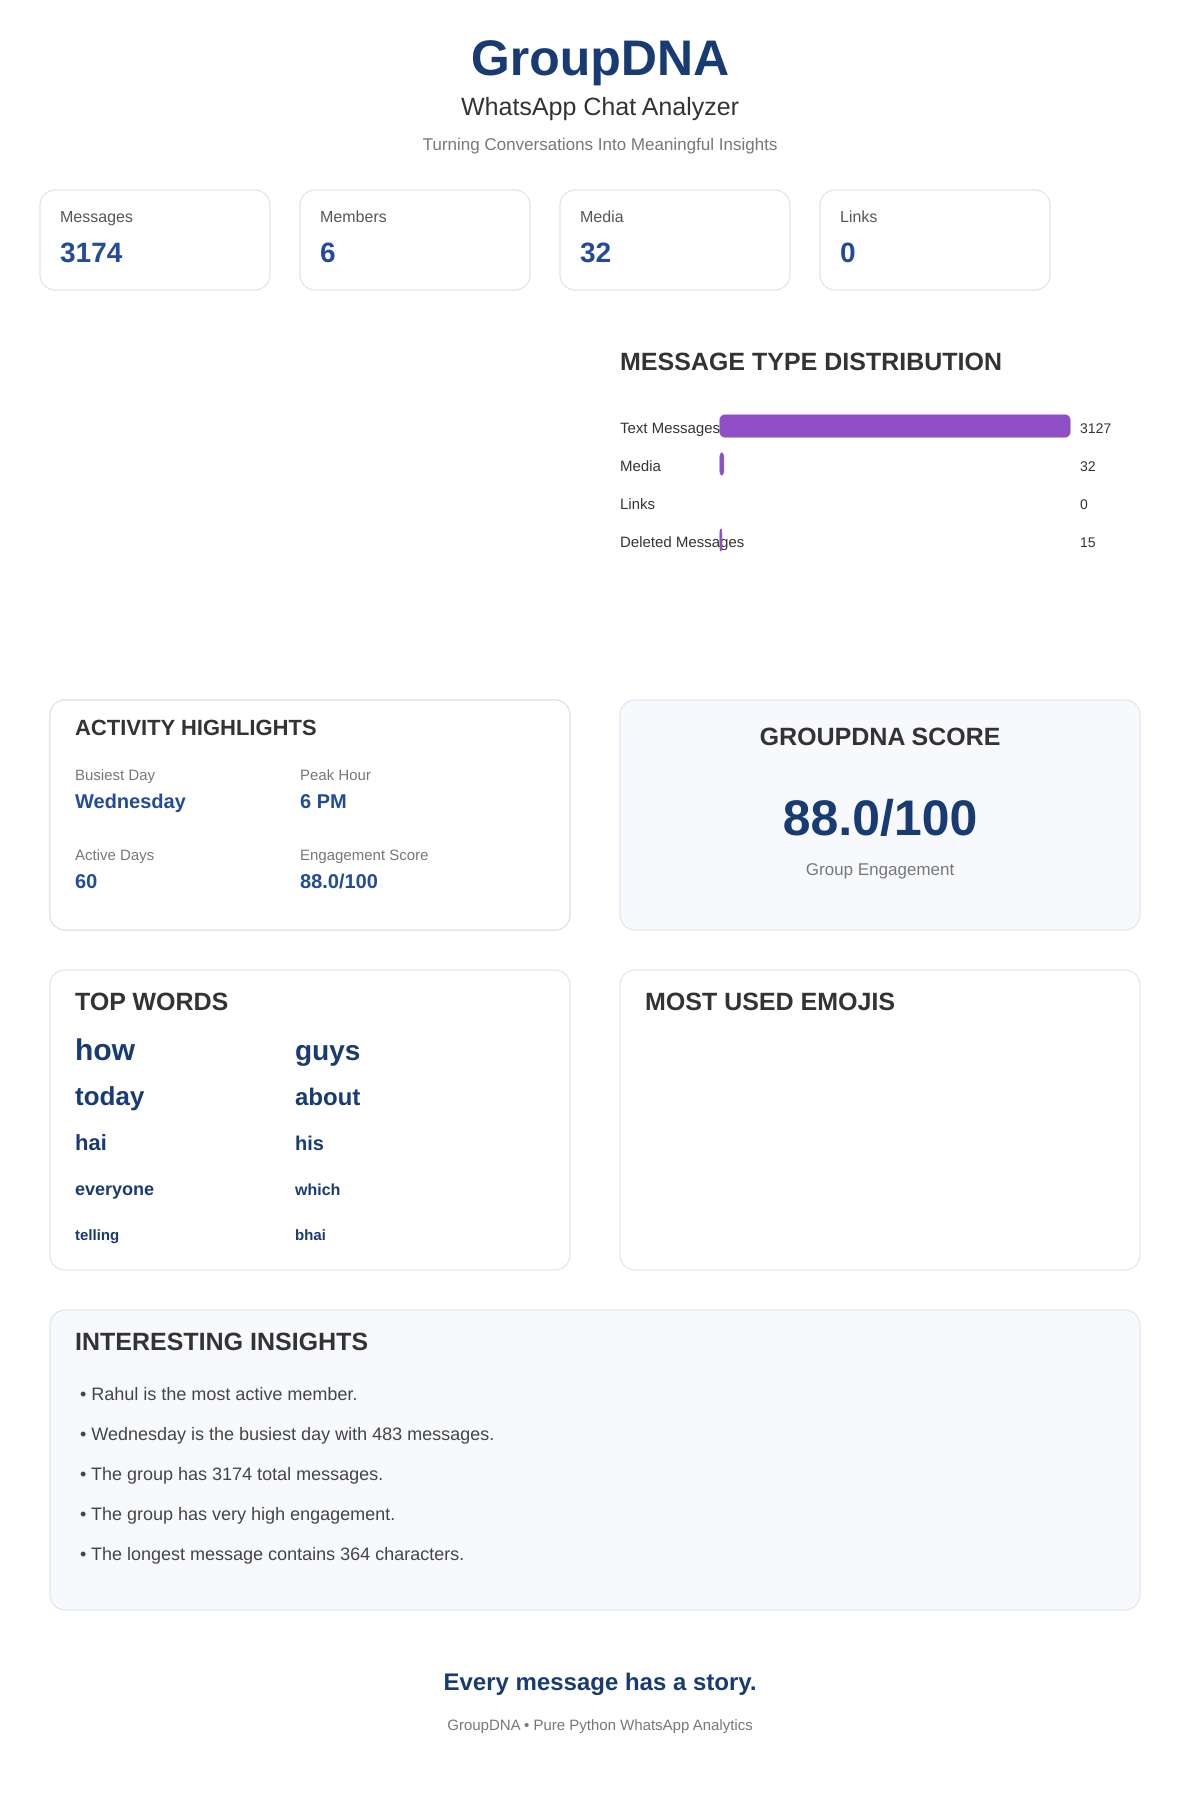

In [ ]:
from IPython.display import SVG, display

display(
    SVG(
        filename="GroupDNA_Dashboard.svg"
    )
)

cell 45 download you poster

In [ ]:
from google.colab import files

files.download(
    "GroupDNA_Dashboard.svg"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
print("cell_id: 7SYH9sxefrko")
print("cell_type: code_cell")
print("content: svg_elements.append(\n    \"</svg>\"\n)\n\nfinal_svg = \"\\n\".join(\n    svg_elements\n)\n\nwith open(\n    \"GroupDNA_Dashboard.svg\",\n    \"w\",\n    encoding=\"utf-8\"\n) as file:\n\n    file.write(\n        final_svg\n    )\n\nprint(\n    \"Poster created successfully!\"\n)\n\nprint(\n    \"GroupDNA_Dashboard.svg\"\n)")

cell_id: 7SYH9sxefrko
cell_type: code_cell
content: svg_elements.append(
    "</svg>"
)

final_svg = "\n".join(
    svg_elements
)

with open(
    "GroupDNA_Dashboard.svg",
    "w",
    encoding="utf-8"
) as file:

    file.write(
        final_svg
    )

print(
    "Poster created successfully!"
)

print(
    "GroupDNA_Dashboard.svg"
)


python

In [ ]:
# ============================================================
# GROUPDNA - FINAL DATA COLLECTION
# PURE PYTHON ONLY
# ============================================================

print("Creating GroupDNA data...")

# ------------------------------------------------------------
# 1. Total messages
# ------------------------------------------------------------

if "messages" in globals():
    total_messages = len(messages)
else:
    total_messages = 0


# ------------------------------------------------------------
# 2. Find members
# ------------------------------------------------------------

members = set()

if "messages" in globals():

    for item in messages:

        sender = str(
            item.get("sender", "")
        ).strip()

        if sender != "":
            members.add(sender)

total_members = len(members)


# ------------------------------------------------------------
# 3. Most active member
# ------------------------------------------------------------

member_counts = {}

if "messages" in globals():

    for item in messages:

        sender = str(
            item.get("sender", "")
        ).strip()

        if sender == "":
            continue

        if sender not in member_counts:
            member_counts[sender] = 0

        member_counts[sender] += 1


if len(member_counts) > 0:

    most_active_member = max(
        member_counts,
        key=member_counts.get
    )

else:

    most_active_member = "Unknown"


# ------------------------------------------------------------
# 4. Busiest day
# ------------------------------------------------------------

if "activity_busiest_day" in globals():

    busiest_day = activity_busiest_day

else:

    busiest_day = "Unknown"


# ------------------------------------------------------------
# 5. Peak hour
# ------------------------------------------------------------

if "activity_peak_hour" in globals():

    peak_hour = activity_peak_hour

else:

    peak_hour = "Unknown"


# ------------------------------------------------------------
# 6. Message types
# ------------------------------------------------------------

message_types = {
    "Text": 0,
    "Media": 0,
    "Links": 0
}

if "messages" in globals():

    for item in messages:

        text = str(
            item.get("message", "")
        )

        if text == "":
            continue

        lower_text = text.lower()

        if (
            "<media omitted>" in lower_text
            or "image omitted" in lower_text
            or "video omitted" in lower_text
            or "audio omitted" in lower_text
            or "sticker omitted" in lower_text
        ):

            message_types["Media"] += 1

        elif (
            "http://" in lower_text
            or "https://" in lower_text
        ):

            message_types["Links"] += 1

        else:

            message_types["Text"] += 1


# ------------------------------------------------------------
# 7. Top contributors
# ------------------------------------------------------------

top_contributors = sorted(
    member_counts.items(),
    key=lambda x: x[1],
    reverse=True
)[:8]


# ------------------------------------------------------------
# 8. Top words
# ------------------------------------------------------------

top_words = []

if "top_words" in globals():

    top_words = top_words


# ------------------------------------------------------------
# 9. Top emojis
# ------------------------------------------------------------

top_emojis = []

if "top_emojis" in globals():

    top_emojis = top_emojis


# ------------------------------------------------------------
# 10. Night owl
# ------------------------------------------------------------

if "night_owl" in globals():

    night_owl_value = night_owl

else:

    night_owl_value = "Unknown"


# ------------------------------------------------------------
# 11. Emoji king
# ------------------------------------------------------------

if "emoji_king" in globals():

    emoji_king_value = emoji_king

else:

    emoji_king_value = "Unknown"


# ------------------------------------------------------------
# 12. Engagement score
# ------------------------------------------------------------

if "group_engagement_score" in globals():

    final_engagement_score = (
        group_engagement_score
    )

elif total_messages > 0:

    final_engagement_score = (
        total_messages / 3000
    ) * 100

    if final_engagement_score > 100:
        final_engagement_score = 100

else:

    final_engagement_score = 0


# ------------------------------------------------------------
# 13. Create final GroupDNA dictionary
# ------------------------------------------------------------

groupdna = {

    "group_name": "Hostel Bois 4ever",

    "total_messages": total_messages,

    "total_members": total_members,

    "most_active_member": most_active_member,

    "busiest_day": busiest_day,

    "peak_hour": peak_hour,

    "message_types": message_types,

    "top_contributors": top_contributors,

    "top_words": top_words,

    "top_emojis": top_emojis,

    "night_owl": night_owl_value,

    "emoji_king": emoji_king_value,

    "engagement_score": final_engagement_score
}


# ------------------------------------------------------------
# 14. Display final data
# ------------------------------------------------------------

print()
print("=" * 60)
print("GROUPDNA DATA CREATED")
print("=" * 60)

print()

print(
    "Group:",
    groupdna["group_name"]
)

print(
    "Total messages:",
    groupdna["total_messages"]
)

print(
    "Total members:",
    groupdna["total_members"]
)

print(
    "Most active member:",
    groupdna["most_active_member"]
)

print(
    "Busiest day:",
    groupdna["busiest_day"]
)

print(
    "Peak hour:",
    groupdna["peak_hour"]
)

print(
    "Engagement score:",
    round(
        groupdna["engagement_score"],
        2
    )
)

print()

print("Message types:")

for name, count in message_types.items():

    print(
        " ",
        name,
        "→",
        count
    )

print()

print("Top contributors:")

for person, count in top_contributors:

    print(
        " ",
        person,
        "→",
        count
    )

print()

print("CELL COMPLETED SUCCESSFULLY")

Creating GroupDNA data...

GROUPDNA DATA CREATED

Group: Hostel Bois 4ever
Total messages: 3174
Total members: 6
Most active member: Rahul
Busiest day: Wednesday
Peak hour: 6 PM
Engagement score: 88.0

Message types:
  Text → 3142
  Media → 32
  Links → 0

Top contributors:
  Rahul → 953
  Priya → 718
  Neha → 635
  Aman → 490
  Karan → 354
  Vikas → 24

CELL COMPLETED SUCCESSFULLY


In [ ]:
display(groupdna)

{'group_name': 'Hostel Bois 4ever',
 'total_messages': 3174,
 'total_members': 6,
 'most_active_member': 'Rahul',
 'busiest_day': 'Wednesday',
 'peak_hour': 18,
 'message_types': {'Text Messages': 3127,
  'Media': 32,
  'Links': 0,
  'Deleted Messages': 15},
 'top_contributors': [('Rahul', 953),
  ('Priya', 718),
  ('Neha', 635),
  ('Aman', 490),
  ('Karan', 354),
  ('Vikas', 24)],
 'top_words': [('how', 321),
  ('guys', 318),
  ('today', 292),
  ('about', 274),
  ('hai', 268),
  ('his', 217),
  ('everyone', 203),
  ('which', 202),
  ('telling', 179),
  ('bhai', 160),
  ('anyone', 157),
  ('one', 157),
  ('started', 150),
  ('scene', 145),
  ('entire', 145)],
 'top_emojis': [],
 'night_owl': ('Aman', 391),
 'emoji_king': None,
 'engagement_score': 88.0}

save

In [ ]:
with open(
    "GroupDNA_results.json",
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        groupdna,
        file,
        indent=4,
        default=str
    )

print(
    "Results saved."
)

Results saved.


download

In [ ]:
files.download(
    "GroupDNA_results.json"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>